# Section 1:

下载IDOT clearance、筛出candidate、用Mapillary找附近images。

## Download IDOT clearance

In [1]:
# 01_download_idot_vertical_clearance_from_arcgis.py

import requests
import geopandas as gpd
import pandas as pd
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

ITEM_ID = "474c97d9a5074e8fbe09268f79ee39be"

# 1. Get ArcGIS item metadata
item_url = f"https://www.arcgis.com/sharing/rest/content/items/{ITEM_ID}"
item_params = {"f": "json"}

item = requests.get(item_url, params=item_params, timeout=30).json()

print("title:", item.get("title"))
print("type:", item.get("type"))
print("url:", item.get("url"))

service_url = item.get("url")
if service_url is None:
    raise ValueError("No service URL found from ArcGIS item metadata.")

title: Vertical Clearance
type: Feature Service
url: https://gis1.dot.illinois.gov/arcgis/rest/services/Permits/TruckPermitRoutes/MapServer/15


In [2]:
# 02a_check_service_url.py

import requests
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

print("service_url:", service_url)

# Correct query URL:
# If service_url already ends with /15, do NOT add /0.
query_url = service_url.rstrip("/") + "/query"

print("query_url:", query_url)

meta = requests.get(service_url, params={"f": "json"}, timeout=30).json()
print("layer name:", meta.get("name"))
print("geometry type:", meta.get("geometryType"))
print("maxRecordCount:", meta.get("maxRecordCount"))

fields = [f["name"] for f in meta.get("fields", [])]
print("num fields:", len(fields))
print(fields[:30])

service_url: https://gis1.dot.illinois.gov/arcgis/rest/services/Permits/TruckPermitRoutes/MapServer/15
query_url: https://gis1.dot.illinois.gov/arcgis/rest/services/Permits/TruckPermitRoutes/MapServer/15/query
layer name: Vertical Clearance
geometry type: esriGeometryPoint
maxRecordCount: 1000
num fields: 43
['OBJECTID', 'ObstructionNumber', 'FT_Height', 'TF_Height', 'TYPE', 'WIDTH_INCHES', 'MarkerSymbol', 'Location', 'Description', 'MaptipsAllDirections', 'Reviewed', 'WEIGHT', 'LENGTH_FEET', 'Snapped', 'FT_TF_Different', 'Structure_Num', 'Shape', 'SubmissionID', 'ConstructionType', 'ConstructionType2', 'DetourRoute', 'Suggestions', 'Suggestions2', 'TrafficAlert', 'TrafficAlert2', 'FromTime', 'ToTime', 'FromDay', 'ToDay', 'Comments']


In [3]:
# 02b_query_arcgis_json.py

import requests
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

params = {
    "f": "json",
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "resultRecordCount": 2000,
}

r = requests.get(query_url, params=params, timeout=60)
print("status:", r.status_code)
print("first 500 chars:", r.text[:500])

r.raise_for_status()
data = r.json()

if "error" in data:
    raise RuntimeError(data["error"])

features = data.get("features", [])
print("features:", len(features))

rows = []
for ft in features:
    attrs = ft.get("attributes", {})
    geom = ft.get("geometry", {})

    x = geom.get("x")
    y = geom.get("y")

    if x is None or y is None:
        continue

    attrs["lon"] = x
    attrs["lat"] = y
    attrs["geometry"] = Point(x, y)
    rows.append(attrs)

gdf = gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:4326")

print("rows in gdf:", len(gdf))
print("columns:", list(gdf.columns))
gdf.head()

status: 200
first 500 chars: {"displayFieldName":"MaptipsAllDirections","fieldAliases":{"OBJECTID":"OBJECTID","ObstructionNumber":"ObstructionNumber","FT_Height":"FT_Height","TF_Height":"TF_Height","TYPE":"TYPE","WIDTH_INCHES":"WIDTH_INCHES","MarkerSymbol":"MarkerSymbol","Location":"Location","Description":"Description","MaptipsAllDirections":"MaptipsAllDirections","Reviewed":"Reviewed","WEIGHT":"WEIGHT","LENGTH_FEET":"LENGTH_FEET","Snapped":"Snapped","FT_TF_Different":"FT_TF_Different","Structure_Num":"Structure_Num","Subm
features: 1000
rows in gdf: 1000
columns: ['OBJECTID', 'ObstructionNumber', 'FT_Height', 'TF_Height', 'TYPE', 'WIDTH_INCHES', 'MarkerSymbol', 'Location', 'Description', 'MaptipsAllDirections', 'Reviewed', 'WEIGHT', 'LENGTH_FEET', 'Snapped', 'FT_TF_Different', 'Structure_Num', 'SubmissionID', 'ConstructionType', 'ConstructionType2', 'DetourRoute', 'Suggestions', 'Suggestions2', 'TrafficAlert', 'TrafficAlert2', 'FromTime', 'ToTime', 'FromDay', 'ToDay', 'Comments', 'St

,OBJECTID,ObstructionNumber,FT_Height,TF_Height,TYPE,WIDTH_INCHES,MarkerSymbol,Location,Description,MaptipsAllDirections,...,ContractValue,LanesClosed,ConstructionTypeDesc,Crossover,CrossoverDesc,EditDate,Editor,lon,lat,geometry
0,1,089X0001,241,234,O,10000,Red,BR20: FREEPORT @ GALENA AVE,"BR20: FREEPORT @ GALENA AVE, SIGN TRUSS, EB: 2...","BR20: FREEPORT @ GALENA AVE, SIGN TRUSS, EB: 2...",...,None,None,None,None,None,None,None,-89.597293,42.280528,POINT (-89.59729 42.28053)
1,2,1019925,171,171,O,10000,Red,IL2: ROCKFORD @ CEDAR ST,"IL2: ROCKFORD @ CEDAR ST, UP RR, NB: 14-03, SB...","IL2: ROCKFORD @ CEDAR ST, UP RR, NB: 14-03, SB...",...,None,None,None,None,None,None,None,-89.097665,42.267052,POINT (-89.09767 42.26705)
2,3,101X0031,217,217,O,10000,Red,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-01","US20: W OF STATE ST, SIGN TRUSS, EB: 18-01",...,None,None,None,None,None,None,None,-89.214512,42.280087,POINT (-89.21451 42.28009)
3,4,101X0032,222,222,O,10000,Red,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-6","US20: W OF STATE ST, SIGN TRUSS, EB: 18-6",...,None,None,None,None,None,None,None,-89.210363,42.280296,POINT (-89.21036 42.2803)
4,5,101X0033,226,226,O,10000,Red,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB...","US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB...",...,None,None,None,None,None,None,None,-89.205002,42.280519,POINT (-89.205 42.28052)


In [4]:
# 02c_save_idot_ground_truth.py

clearance_cols = [
    c for c in gdf.columns
    if any(k in c.lower() for k in ["clear", "height", "vert", "vc", "cl"])
]

route_cols = [
    c for c in gdf.columns
    if any(k in c.lower() for k in ["route", "road", "highway", "structure", "str", "location"])
]

print("Possible clearance columns:", clearance_cols)
print("Possible route/structure columns:", route_cols)

gdf.to_file("outputs/idot_vertical_clearance_wgs84.geojson", driver="GeoJSON")

cols_to_save = ["lat", "lon"] + clearance_cols + route_cols
cols_to_save = list(dict.fromkeys([c for c in cols_to_save if c in gdf.columns]))

gdf[cols_to_save].to_csv("outputs/idot_clearance_points.csv", index=False)

print("saved outputs/idot_vertical_clearance_wgs84.geojson")
print("saved outputs/idot_clearance_points.csv")

Possible clearance columns: ['FT_Height', 'TF_Height', 'LanesClosed']
Possible route/structure columns: ['ObstructionNumber', 'Location', 'Structure_Num', 'ConstructionType', 'ConstructionType2', 'DetourRoute', 'District', 'ConstructionTypeDesc']
saved outputs/idot_vertical_clearance_wgs84.geojson
saved outputs/idot_clearance_points.csv


## Clean, Candidate, Mapillary

In [5]:
# 03a_clean_clearance_values.py

import pandas as pd
import geopandas as gpd
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

gdf = gpd.read_file("outputs/idot_vertical_clearance_wgs84.geojson")

print("raw rows:", len(gdf))
print("columns:", list(gdf.columns))

# Your layer has FT_Height and TF_Height, but no IN_Height.
# Use FT_Height as clearance in feet for now.
gdf["FT_Height"] = pd.to_numeric(gdf["FT_Height"], errors="coerce")
gdf["TF_Height"] = pd.to_numeric(gdf["TF_Height"], errors="coerce")

gdf["clearance_ft"] = gdf["FT_Height"]
gdf["clearance_m"] = gdf["clearance_ft"] * 0.3048

gdf = gdf[gdf.geometry.notna()].copy()
gdf = gdf[gdf["clearance_ft"].notna()].copy()
gdf = gdf[gdf["clearance_ft"] > 0].copy()

if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326")
else:
    gdf = gdf.to_crs("EPSG:4326")

gdf["lon"] = gdf.geometry.x
gdf["lat"] = gdf.geometry.y

show_cols = [
    "Structure_Num",
    "ObstructionNumber",
    "Location",
    "FT_Height",
    "TF_Height",
    "clearance_ft",
    "clearance_m",
    "lat",
    "lon",
]
show_cols = [c for c in show_cols if c in gdf.columns]

print("clean rows:", len(gdf))
print(gdf[show_cols].head())

gdf.to_file("outputs/idot_clearance_clean.geojson", driver="GeoJSON")
gdf.to_csv("outputs/idot_clearance_clean.csv", index=False)

print("saved outputs/idot_clearance_clean.geojson")
print("saved outputs/idot_clearance_clean.csv")

raw rows: 1000
columns: ['OBJECTID', 'ObstructionNumber', 'FT_Height', 'TF_Height', 'TYPE', 'WIDTH_INCHES', 'MarkerSymbol', 'Location', 'Description', 'MaptipsAllDirections', 'Reviewed', 'WEIGHT', 'LENGTH_FEET', 'Snapped', 'FT_TF_Different', 'Structure_Num', 'SubmissionID', 'ConstructionType', 'ConstructionType2', 'DetourRoute', 'Suggestions', 'Suggestions2', 'TrafficAlert', 'TrafficAlert2', 'FromTime', 'ToTime', 'FromDay', 'ToDay', 'Comments', 'StaffComments', 'GlobalID', 'District', 'WebAddress', 'ContractNumber', 'Contractor', 'ContractValue', 'LanesClosed', 'ConstructionTypeDesc', 'Crossover', 'CrossoverDesc', 'EditDate', 'Editor', 'lon', 'lat', 'geometry']
clean rows: 1000
  Structure_Num ObstructionNumber                     Location  FT_Height  \
0    089X0001_3          089X0001  BR20: FREEPORT @ GALENA AVE        241   
1     1019925_5           1019925     IL2: ROCKFORD @ CEDAR ST        171   
2    101X0031_3          101X0031          US20: W OF STATE ST        217   
3    

In [6]:
# 03b_pick_candidate_sites.py

import pandas as pd
import geopandas as gpd
from pathlib import Path

Path("outputs/candidates").mkdir(parents=True, exist_ok=True)

gdf = gpd.read_file("outputs/idot_clearance_clean.geojson")

candidate = gdf[
    (gdf["clearance_ft"] >= 12) &
    (gdf["clearance_ft"] <= 18)
].copy()

if len(candidate) < 10:
    candidate = gdf.copy()

candidate = candidate.sample(min(20, len(candidate)), random_state=42).copy()
candidate["site_id"] = [f"site_{i:03d}" for i in range(len(candidate))]

cols = [
    "site_id",
    "Structure_Num",
    "ObstructionNumber",
    "Location",
    "FT_Height",
    "TF_Height",
    "clearance_ft",
    "clearance_m",
    "lat",
    "lon",
]
cols = [c for c in cols if c in candidate.columns]

candidate[cols].to_csv("outputs/candidates/candidate_sites.csv", index=False)
candidate.to_file("outputs/candidates/candidate_sites.geojson", driver="GeoJSON")

print("candidate rows:", len(candidate))
print(candidate[cols])

candidate rows: 20
      site_id Structure_Num ObstructionNumber  \
521  site_000   0620050_551           0620050   
737  site_001   0720179_784           0720179   
740  site_002   0720182_787           0720182   
660  site_003  072X0048_703          072X0048   
411  site_004   0370112_508           0370112   
678  site_005   0720123_824           0720123   
626  site_006   0720076_767           0720076   
513  site_007   0780022_543           0780022   
859  site_008  1020051_1076           1020051   
136  site_009   0710055_172           0710055   
811  site_010   0900141_862           0900141   
76   site_011   0490016_109           0490016   
636  site_012   0720071_777           0720071   
973  site_013  0500223_1208           0500223   
938  site_014  0500199_1164           0500199   
899  site_015  0500027_1119           0500027   
280  site_016   0810156_347           0810156   
883  site_017  0530135_1101           0530135   
761  site_018   0900074_809           0900074   
3

In [7]:
# 03c_fast_1_use_fewer_sites.py

import pandas as pd

candidate_all = pd.read_csv("outputs/candidates/candidate_sites.csv")

# 先只跑3个site，确认Mapillary API和coverage没问题
candidate = candidate_all.head(3).copy()

print("total candidate sites:", len(candidate_all))
print("running sites now:", len(candidate))
print(candidate[["site_id", "Location", "clearance_ft", "lat", "lon"]])

total candidate sites: 20
running sites now: 3
    site_id          Location  clearance_ft        lat        lon
0  site_000  I-39/US51: UNDER           194  41.028190 -89.056530
1  site_001       I-74: UNDER           189  40.694741 -89.587330
2  site_002  I-74 RAMP: UNDER           206  40.693865 -89.586135


NameError: name 'offset_latlon' is not defined

In [ ]:
# 03c_fast_3_query_only_3_sites.py

rows = []

for _, site in candidate.iterrows():
    grid = make_small_grid_points(site.lat, site.lon, spacing_m=60)

    print("querying", site.site_id, "grid points:", len(grid))

    for q in grid:
        images = query_mapillary_images(
            q["query_lat"],
            q["query_lon"],
            radius_m=50,
            limit=20,
        )

        for img in images:
            geom = img.get("computed_geometry") or img.get("geometry") or {}
            coords = geom.get("coordinates", [None, None])

            img_lon, img_lat = coords[0], coords[1]

            dist_m = None
            if img_lat is not None and img_lon is not None:
                dist_m = haversine_m(site.lat, site.lon, img_lat, img_lon)

            rows.append({
                "site_id": site.site_id,
                "gt_lat": site.lat,
                "gt_lon": site.lon,
                "clearance_ft": site.clearance_ft,
                "clearance_m": site.clearance_m,
                "structure_num": site.get("Structure_Num", None),
                "location": site.get("Location", None),
                "query_lat": q["query_lat"],
                "query_lon": q["query_lon"],
                "query_north_m": q["north_m"],
                "query_east_m": q["east_m"],
                "image_id": img.get("id"),
                "sequence": img.get("sequence"),
                "img_lat": img_lat,
                "img_lon": img_lon,
                "distance_m": dist_m,
                "compass_angle": img.get("compass_angle"),
                "captured_at": img.get("captured_at"),
                "thumb_2048_url": img.get("thumb_2048_url"),
            })

df = pd.DataFrame(rows)

if len(df) == 0:
    print("No Mapillary images found in first 3 sites.")
else:
    df = df.drop_duplicates(subset=["site_id", "image_id"]).copy()
    df = df.sort_values(["site_id", "distance_m"]).reset_index(drop=True)

    seq_summary = (
        df.groupby(["site_id", "sequence"], dropna=False)
        .agg(
            num_images=("image_id", "count"),
            min_distance_m=("distance_m", "min"),
            median_distance_m=("distance_m", "median"),
            clearance_ft=("clearance_ft", "first"),
            clearance_m=("clearance_m", "first"),
            location=("location", "first"),
        )
        .reset_index()
        .sort_values(["site_id", "num_images", "min_distance_m"], ascending=[True, False, True])
    )

    df.to_csv("outputs/mapillary/mapillary_images_near_candidates_fast.csv", index=False)
    seq_summary.to_csv("outputs/mapillary/mapillary_sequence_summary_fast.csv", index=False)

    print("num matched images:", len(df))
    print("num matched sites:", df["site_id"].nunique())
    print("num sequences:", df["sequence"].nunique())

    display(seq_summary.head(20))

## Show the sequence of data


In [ ]:
# 04a_fix_idot_clearance_encoding.py

import pandas as pd
import geopandas as gpd
from pathlib import Path

gdf = gpd.read_file("outputs/idot_vertical_clearance_wgs84.geojson")

gdf["FT_Height_raw"] = pd.to_numeric(gdf["FT_Height"], errors="coerce")

def decode_idot_height(x):
    """
    IDOT FT_Height appears encoded like:
    189 -> 18 ft 9 in
    194 -> 19 ft 4 in
    140 -> 14 ft 0 in
    """
    if pd.isna(x):
        return None, None, None

    x = int(x)
    ft = x // 10
    inch = x % 10

    clearance_ft = ft + inch / 12.0
    clearance_m = clearance_ft * 0.3048

    return ft, inch, clearance_ft, clearance_m

decoded = gdf["FT_Height_raw"].apply(decode_idot_height)

gdf["clearance_feet_part"] = decoded.apply(lambda t: t[0] if t else None)
gdf["clearance_inches_part"] = decoded.apply(lambda t: t[1] if t else None)
gdf["clearance_ft"] = decoded.apply(lambda t: t[2] if t else None)
gdf["clearance_m"] = decoded.apply(lambda t: t[3] if t else None)

gdf = gdf[gdf.geometry.notna()].copy()
gdf = gdf[gdf["clearance_ft"].notna()].copy()
gdf = gdf[gdf["clearance_ft"] > 0].copy()

if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326")
else:
    gdf = gdf.to_crs("EPSG:4326")

gdf["lon"] = gdf.geometry.x
gdf["lat"] = gdf.geometry.y

print(gdf[[
    "Structure_Num",
    "Location",
    "FT_Height_raw",
    "clearance_feet_part",
    "clearance_inches_part",
    "clearance_ft",
    "clearance_m",
    "lat",
    "lon",
]].head(20))

gdf.to_file("outputs/idot_clearance_clean.geojson", driver="GeoJSON")
gdf.to_csv("outputs/idot_clearance_clean.csv", index=False)

print("saved corrected ground truth")

In [ ]:
# 04b_update_mapillary_ground_truth_values.py

import pandas as pd
import geopandas as gpd

img_df = pd.read_csv("outputs/mapillary/mapillary_images_near_candidates_fast.csv")
gt_gdf = gpd.read_file("outputs/idot_clearance_clean.geojson")

# candidate_sites.csv was generated before fixing clearance,
# so update by nearest exact lat/lon match. For the current 3 sites this is enough.
gt_cols = [
    "lat",
    "lon",
    "FT_Height_raw",
    "clearance_feet_part",
    "clearance_inches_part",
    "clearance_ft",
    "clearance_m",
]

gt_small = gt_gdf[gt_cols].copy()
gt_small = gt_small.rename(columns={
    "lat": "gt_lat",
    "lon": "gt_lon",
})

img_df = img_df.drop(columns=[
    c for c in [
        "clearance_ft",
        "clearance_m",
        "FT_Height_raw",
        "clearance_feet_part",
        "clearance_inches_part",
    ]
    if c in img_df.columns
])

img_df = img_df.merge(gt_small, on=["gt_lat", "gt_lon"], how="left")

img_df.to_csv("outputs/mapillary/mapillary_images_near_candidates_fast_fixed_gt.csv", index=False)

seq_summary = (
    img_df.groupby(["site_id", "sequence"], dropna=False)
    .agg(
        num_images=("image_id", "count"),
        min_distance_m=("distance_m", "min"),
        median_distance_m=("distance_m", "median"),
        clearance_ft=("clearance_ft", "first"),
        clearance_m=("clearance_m", "first"),
        location=("location", "first"),
    )
    .reset_index()
    .sort_values(["site_id", "num_images", "min_distance_m"], ascending=[True, False, True])
)

seq_summary.to_csv("outputs/mapillary/mapillary_sequence_summary_fast_fixed_gt.csv", index=False)

display(seq_summary.head(30))

In [ ]:
# 04c_select_best_sequence_for_mapanything.py

import pandas as pd
from pathlib import Path

img_df = pd.read_csv("outputs/mapillary/mapillary_images_near_candidates_fast_fixed_gt.csv")
seq_summary = pd.read_csv("outputs/mapillary/mapillary_sequence_summary_fast_fixed_gt.csv")

# Scoring:
# enough images, close to GT point, not too sparse
seq_summary["score"] = (
    seq_summary["num_images"] * 2
    - seq_summary["min_distance_m"] * 0.2
    - seq_summary["median_distance_m"] * 0.05
)

best = seq_summary.sort_values("score", ascending=False).iloc[0]

best_site_id = best["site_id"]
best_sequence = best["sequence"]

print("BEST SITE:", best_site_id)
print("BEST SEQUENCE:", best_sequence)
print(best)

best_imgs = img_df[
    (img_df["site_id"] == best_site_id) &
    (img_df["sequence"] == best_sequence)
].copy()

best_imgs = best_imgs.sort_values("captured_at").reset_index(drop=True)

Path("outputs/mapanything_input").mkdir(parents=True, exist_ok=True)

best_imgs.to_csv("outputs/mapanything_input/best_sequence_images.csv", index=False)

print("num images in best sequence:", len(best_imgs))
display(best_imgs[[
    "site_id",
    "sequence",
    "image_id",
    "distance_m",
    "clearance_ft",
    "clearance_m",
    "thumb_2048_url",
]].head(10))

In [ ]:
# 05a_download_best_sequence_images.py

import pandas as pd
import requests
from pathlib import Path
from tqdm import tqdm

best_imgs = pd.read_csv("outputs/mapanything_input/best_sequence_images.csv")

seq_dir = Path("outputs/mapanything_input/images")
seq_dir.mkdir(parents=True, exist_ok=True)

def download_image(url, out_path):
    if out_path.exists() and out_path.stat().st_size > 0:
        return True

    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        print("download failed:", r.status_code, url[:80])
        return False

    out_path.write_bytes(r.content)
    return True

downloaded = []

for i, row in tqdm(best_imgs.iterrows(), total=len(best_imgs)):
    image_id = str(row["image_id"])
    url = row["thumb_2048_url"]

    out_path = seq_dir / f"{i:04d}_{image_id}.jpg"
    ok = download_image(url, out_path)

    downloaded.append({
        "idx": i,
        "image_id": image_id,
        "path": str(out_path),
        "ok": ok,
        "distance_m": row["distance_m"],
    })

downloaded_df = pd.DataFrame(downloaded)
downloaded_df.to_csv("outputs/mapanything_input/downloaded_images.csv", index=False)

print("downloaded:", downloaded_df["ok"].sum(), "/", len(downloaded_df))
display(downloaded_df.head())

In [ ]:
# 05b_prepare_single_image_input.py

import shutil
import pandas as pd
from pathlib import Path

downloaded_df = pd.read_csv("outputs/mapanything_input/downloaded_images.csv")
best_imgs = pd.read_csv("outputs/mapanything_input/best_sequence_images.csv")

single_dir = Path("outputs/mapanything_input/single_image")
single_dir.mkdir(parents=True, exist_ok=True)

# choose closest image to IDOT GT point
closest = downloaded_df[downloaded_df["ok"] == True].sort_values("distance_m").iloc[0]

src = Path(closest["path"])
dst = single_dir / src.name

shutil.copy2(src, dst)

single_meta = best_imgs[best_imgs["image_id"].astype(str) == str(closest["image_id"])].copy()
single_meta.to_csv("outputs/mapanything_input/single_image_metadata.csv", index=False)

print("single image selected:")
print("image_id:", closest["image_id"])
print("distance_m:", closest["distance_m"])
print("path:", dst)

display(single_meta[[
    "site_id",
    "sequence",
    "image_id",
    "distance_m",
    "clearance_ft",
    "clearance_m",
    "location",
]])

In [ ]:
# 05c_save_ground_truth_metadata.py

import json
import pandas as pd
from pathlib import Path

best_imgs = pd.read_csv("outputs/mapanything_input/best_sequence_images.csv")

first = best_imgs.iloc[0]

gt = {
    "site_id": first["site_id"],
    "sequence": first["sequence"],
    "location": first["location"],
    "gt_lat": float(first["gt_lat"]),
    "gt_lon": float(first["gt_lon"]),
    "clearance_ft": float(first["clearance_ft"]),
    "clearance_m": float(first["clearance_m"]),
    "structure_num": str(first.get("structure_num", "")),
    "source": "IDOT Vertical Clearance + Mapillary sequence imagery",
    "notes": "clearance_ft decoded from IDOT FT_Height encoding, e.g. 189 -> 18 ft 9 in",
}

out_path = Path("outputs/mapanything_input/ground_truth.json")
out_path.write_text(json.dumps(gt, indent=2))

print(json.dumps(gt, indent=2))
print("saved:", out_path)

In [ ]:
from pathlib import Path

for p in [
    "outputs/mapanything_input/images",
    "outputs/mapanything_input/single_image",
    "outputs/mapanything_input/ground_truth.json",
]:
    path = Path(p)
    print(p, "exists:", path.exists(), "num files:", len(list(path.glob('*'))) if path.is_dir() else "-")

# MapAnything

In [ ]:
# 06a_clone_and_install_mapanything.py

import os
from pathlib import Path

repo_dir = Path("external/map-anything")

if not repo_dir.exists():
    !mkdir -p external
    !git clone https://github.com/facebookresearch/map-anything.git external/map-anything
else:
    print("repo already exists:", repo_dir)

%cd external/map-anything

!pip install -e .

In [ ]:
# 06b_inspect_mapanything_repo.py

from pathlib import Path

root = Path(".")
for p in root.rglob("*.py"):
    s = str(p)
    if any(k in s.lower() for k in ["demo", "infer", "run", "predict", "reconstruct"]):
        print(s)

print("\nTop-level files:")
for p in root.iterdir():
    print(p)

In [ ]:
# 06c_search_readme_for_inference_commands.py

from pathlib import Path

for name in ["README.md", "INSTALL.md", "docs/README.md"]:
    p = Path(name)
    if p.exists():
        text = p.read_text(errors="ignore")
        lines = text.splitlines()

        print(f"\n===== {name} =====")
        for i, line in enumerate(lines):
            low = line.lower()
            if any(k in low for k in ["inference", "demo", "predict", "reconstruct", "ply", "viewer", "rerun"]):
                start = max(0, i - 3)
                end = min(len(lines), i + 8)
                print("\n".join(lines[start:end]))
                print("-" * 80)

In [ ]:
# 07a_check_gpu_and_paths.py

import os
from pathlib import Path

# You should currently be inside external/map-anything.
print("cwd:", os.getcwd())

images_dir = Path("../../outputs/mapanything_input/images").resolve()
single_dir = Path("../../outputs/mapanything_input/single_image").resolve()
out_dir = Path("../../outputs/mapanything_output").resolve()

out_dir.mkdir(parents=True, exist_ok=True)

print("images_dir:", images_dir, images_dir.exists(), len(list(images_dir.glob("*.jpg"))))
print("single_dir:", single_dir, single_dir.exists(), len(list(single_dir.glob("*.jpg"))))
print("out_dir:", out_dir)

!nvidia-smi

In [ ]:
# 07b_stop_and_make_small_subset.py

import shutil
from pathlib import Path

src_dir = Path("../../outputs/mapanything_input/images").resolve()
dst_dir = Path("../../outputs/mapanything_input/images_6").resolve()

dst_dir.mkdir(parents=True, exist_ok=True)

for old in dst_dir.glob("*.jpg"):
    old.unlink()

imgs = sorted(src_dir.glob("*.jpg"))

# 6张均匀sample，先确认pipeline能跑通
idxs = [round(i * (len(imgs) - 1) / 5) for i in range(6)]

for j, idx in enumerate(idxs):
    src = imgs[idx]
    dst = dst_dir / f"{j:04d}_{src.name}"
    shutil.copy2(src, dst)

print("created:", dst_dir)
print("num files:", len(list(dst_dir.glob("*.jpg"))))
print([p.name for p in sorted(dst_dir.glob("*.jpg"))])

In [ ]:
# 07b_run_mapanything_6_images_to_glb.py

from pathlib import Path

images_dir = Path("../../outputs/mapanything_input/images_6").resolve()
out_path = Path("../../outputs/mapanything_output/sequence_6_mapanything.glb").resolve()

cmd = f"""
python scripts/demo_images_only_inference.py \
  --image_folder "{images_dir}" \
  --save_glb \
  --output_path "{out_path}" \
  --apache
"""

print(cmd)
!{cmd}

In [ ]:
# 07c_check_6_image_output.py

from pathlib import Path

out_path = Path("../../outputs/mapanything_output/sequence_6_mapanything.glb").resolve()

print("exists:", out_path.exists())
print("size MB:", out_path.stat().st_size / 1024 / 1024 if out_path.exists() else None)

# Change to GPU

In [9]:
# 08a_after_gpu_runtime_restart.py

from pathlib import Path
import os

print("cwd before:", os.getcwd())

repo_dir = Path("external/map-anything")
print("repo exists:", repo_dir.exists())

%cd external/map-anything

!pip install -e .
!nvidia-smi

cwd before: /content
repo exists: False
[Errno 2] No such file or directory: 'external/map-anything'
/content
Obtaining file:///content
ERROR: file:///content does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
Wed May 20 05:00:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |          

In [10]:
# 08b_run_6_images_on_gpu.py

from pathlib import Path

images_dir = Path("../../outputs/mapanything_input/images_6").resolve()
out_path = Path("../../outputs/mapanything_output/sequence_6_mapanything.glb").resolve()

print("images:", images_dir, images_dir.exists(), len(list(images_dir.glob("*.jpg"))))
print("out:", out_path)

cmd = f"""
python scripts/demo_images_only_inference.py \
  --image_folder "{images_dir}" \
  --save_glb \
  --output_path "{out_path}" \
  --apache
"""

print(cmd)
!{cmd}

images: /outputs/mapanything_input/images_6 False 0
out: /outputs/mapanything_output/sequence_6_mapanything.glb

python scripts/demo_images_only_inference.py   --image_folder "/outputs/mapanything_input/images_6"   --save_glb   --output_path "/outputs/mapanything_output/sequence_6_mapanything.glb"   --apache

python3: can't open file '/content/scripts/demo_images_only_inference.py': [Errno 2] No such file or directory


In [11]:
# 08c_check_output.py

from pathlib import Path

out_path = Path("../../outputs/mapanything_output/sequence_6_mapanything.glb").resolve()

print("exists:", out_path.exists())
print("size MB:", out_path.stat().st_size / 1024 / 1024 if out_path.exists() else None)

exists: False
size MB: None


In [12]:
# 00_check_current_state.py

from pathlib import Path
import os

print("cwd:", os.getcwd())

paths = [
    "outputs/idot_vertical_clearance_wgs84.geojson",
    "outputs/idot_clearance_clean.geojson",
    "outputs/candidates/candidate_sites.csv",
    "outputs/mapillary/mapillary_images_near_candidates_fast.csv",
    "outputs/mapillary/mapillary_images_near_candidates_fast_fixed_gt.csv",
    "outputs/mapanything_input/images",
    "outputs/mapanything_input/single_image",
    "outputs/mapanything_input/ground_truth.json",
    "external/map-anything",
]

for p in paths:
    path = Path(p)
    if path.is_dir():
        print(p, "DIR exists:", True, "num files:", len(list(path.glob('*'))))
    else:
        print(p, "FILE exists:", path.exists())

cwd: /content
outputs/idot_vertical_clearance_wgs84.geojson FILE exists: True
outputs/idot_clearance_clean.geojson FILE exists: True
outputs/candidates/candidate_sites.csv FILE exists: True
outputs/mapillary/mapillary_images_near_candidates_fast.csv FILE exists: False
outputs/mapillary/mapillary_images_near_candidates_fast_fixed_gt.csv FILE exists: False
outputs/mapanything_input/images FILE exists: False
outputs/mapanything_input/single_image FILE exists: False
outputs/mapanything_input/ground_truth.json FILE exists: False
external/map-anything FILE exists: False


In [13]:
# 03c_restore_fast_query.py

import os
import time
import requests
import pandas as pd
from pathlib import Path
from math import radians, sin, cos, sqrt, atan2


MAPILLARY_TOKEN = "<YOUR_MAPILLARY_TOKEN>"

Path("outputs/mapillary").mkdir(parents=True, exist_ok=True)

candidate_all = pd.read_csv("outputs/candidates/candidate_sites.csv")
candidate = candidate_all.head(3).copy()

print("running sites:", len(candidate))
display(candidate[["site_id", "Location", "clearance_ft", "lat", "lon"]])

def offset_latlon(lat, lon, north_m, east_m):
    lat_offset = north_m / 111_320
    lon_offset = east_m / (111_320 * cos(radians(lat)))
    return lat + lat_offset, lon + lon_offset

def make_small_grid_points(lat, lon, spacing_m=60):
    points = []
    for north_m in [-spacing_m, 0, spacing_m]:
        for east_m in [-spacing_m, 0, spacing_m]:
            qlat, qlon = offset_latlon(lat, lon, north_m, east_m)
            points.append({
                "query_lat": qlat,
                "query_lon": qlon,
                "north_m": north_m,
                "east_m": east_m,
            })
    return points

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2) ** 2
    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

def query_mapillary_images(lat, lon, radius_m=50, limit=20):
    url = "https://graph.mapillary.com/images"
    params = {
        "access_token": MAPILLARY_TOKEN,
        "fields": "id,geometry,computed_geometry,sequence,compass_angle,captured_at,thumb_2048_url",
        "lat": float(lat),
        "lng": float(lon),
        "radius": min(radius_m, 50),
        "limit": limit,
    }

    r = requests.get(url, params=params, timeout=30)

    if r.status_code != 200:
        print("ERROR", r.status_code, lat, lon, r.text[:200])
        return []

    return r.json().get("data", [])

rows = []

for _, site in candidate.iterrows():
    grid = make_small_grid_points(site.lat, site.lon, spacing_m=60)
    print("querying", site.site_id, "grid points:", len(grid))

    for q in grid:
        images = query_mapillary_images(q["query_lat"], q["query_lon"], radius_m=50, limit=20)
        time.sleep(0.05)

        for img in images:
            geom = img.get("computed_geometry") or img.get("geometry") or {}
            coords = geom.get("coordinates", [None, None])
            img_lon, img_lat = coords[0], coords[1]

            dist_m = None
            if img_lat is not None and img_lon is not None:
                dist_m = haversine_m(site.lat, site.lon, img_lat, img_lon)

            rows.append({
                "site_id": site.site_id,
                "gt_lat": site.lat,
                "gt_lon": site.lon,
                "clearance_ft": site.clearance_ft,
                "clearance_m": site.clearance_m,
                "structure_num": site.get("Structure_Num", None),
                "location": site.get("Location", None),
                "query_lat": q["query_lat"],
                "query_lon": q["query_lon"],
                "query_north_m": q["north_m"],
                "query_east_m": q["east_m"],
                "image_id": img.get("id"),
                "sequence": img.get("sequence"),
                "img_lat": img_lat,
                "img_lon": img_lon,
                "distance_m": dist_m,
                "compass_angle": img.get("compass_angle"),
                "captured_at": img.get("captured_at"),
                "thumb_2048_url": img.get("thumb_2048_url"),
            })

df = pd.DataFrame(rows)

if len(df) == 0:
    raise RuntimeError("No Mapillary images found. Check token or candidate sites.")

df = df.drop_duplicates(subset=["site_id", "image_id"]).copy()
df = df.sort_values(["site_id", "distance_m"]).reset_index(drop=True)

df.to_csv("outputs/mapillary/mapillary_images_near_candidates_fast.csv", index=False)

seq_summary = (
    df.groupby(["site_id", "sequence"], dropna=False)
    .agg(
        num_images=("image_id", "count"),
        min_distance_m=("distance_m", "min"),
        median_distance_m=("distance_m", "median"),
        clearance_ft=("clearance_ft", "first"),
        clearance_m=("clearance_m", "first"),
        location=("location", "first"),
    )
    .reset_index()
    .sort_values(["site_id", "num_images", "min_distance_m"], ascending=[True, False, True])
)

seq_summary.to_csv("outputs/mapillary/mapillary_sequence_summary_fast.csv", index=False)

print("num matched images:", len(df))
print("num matched sites:", df["site_id"].nunique())
print("num sequences:", df["sequence"].nunique())
display(seq_summary.head(20))

running sites: 3


,site_id,Location,clearance_ft,lat,lon
0,site_000,I-39/US51: UNDER,194,41.028190,-89.056530
1,site_001,I-74: UNDER,189,40.694741,-89.587330
2,site_002,I-74 RAMP: UNDER,206,40.693865,-89.586135


querying site_000 grid points: 9
querying site_001 grid points: 9
querying site_002 grid points: 9
num matched images: 359
num matched sites: 3
num sequences: 22


,site_id,sequence,num_images,min_distance_m,median_distance_m,clearance_ft,clearance_m,location
8,site_000,nU2zPmyNlXq68IgcC1SFH3,25,51.351250,94.415119,194,59.1312,I-39/US51: UNDER
5,site_000,Qs5DhAktKixcv8z3P0MfJa,23,43.138094,71.872932,194,59.1312,I-39/US51: UNDER
10,site_000,wPm7gApesarHZjfB4XKdO2,13,1.991939,51.710458,194,59.1312,I-39/US51: UNDER
2,site_000,6OTC1RJhDIjgUoQ3GVn2L7,11,2.510606,35.406599,194,59.1312,I-39/US51: UNDER
0,site_000,3fq06ThCLBGaoysxSEZVQP,8,5.681564,38.319801,194,59.1312,I-39/US51: UNDER
7,site_000,nQ1IkpVylfthaewcYXzJ6u,8,26.777504,58.577404,194,59.1312,I-39/US51: UNDER
1,site_000,4s5Itnu76VlSc03kf8ABUh,6,3.355029,52.511832,194,59.1312,I-39/US51: UNDER
3,site_000,AybPstTmKJ7dwhvMU1xREG,4,27.998456,44.977646,194,59.1312,I-39/US51: UNDER
9,site_000,qVQ3BcuNpP1roSgURkMm4T,3,4.015513,54.888551,194,59.1312,I-39/US51: UNDER
4,site_000,KrvitYHTsBXOgmxha65E7A,3,80.658846,100.344988,194,59.1312,I-39/US51: UNDER


In [14]:
# 04_05_restore_best_sequence_and_download.py

import json
import shutil
import requests
import pandas as pd
import geopandas as gpd
from pathlib import Path
from tqdm import tqdm

Path("outputs/mapanything_input/images").mkdir(parents=True, exist_ok=True)
Path("outputs/mapanything_input/single_image").mkdir(parents=True, exist_ok=True)

img_df = pd.read_csv("outputs/mapillary/mapillary_images_near_candidates_fast.csv")
gt_gdf = gpd.read_file("outputs/idot_clearance_clean.geojson")

# 如果clean里已经有正确clearance_ft=18.75，就直接merge
gt_small = gt_gdf[["lat", "lon", "clearance_ft", "clearance_m"]].rename(
    columns={"lat": "gt_lat", "lon": "gt_lon"}
)

img_df = img_df.drop(columns=[c for c in ["clearance_ft", "clearance_m"] if c in img_df.columns])
img_df = img_df.merge(gt_small, on=["gt_lat", "gt_lon"], how="left")

seq_summary = (
    img_df.groupby(["site_id", "sequence"], dropna=False)
    .agg(
        num_images=("image_id", "count"),
        min_distance_m=("distance_m", "min"),
        median_distance_m=("distance_m", "median"),
        clearance_ft=("clearance_ft", "first"),
        clearance_m=("clearance_m", "first"),
        location=("location", "first"),
    )
    .reset_index()
)

seq_summary["score"] = (
    seq_summary["num_images"] * 2
    - seq_summary["min_distance_m"] * 0.2
    - seq_summary["median_distance_m"] * 0.05
)

best = seq_summary.sort_values("score", ascending=False).iloc[0]
best_site_id = best["site_id"]
best_sequence = best["sequence"]

print("BEST SITE:", best_site_id)
print("BEST SEQUENCE:", best_sequence)
print(best)

best_imgs = img_df[
    (img_df["site_id"] == best_site_id) &
    (img_df["sequence"] == best_sequence)
].copy()

best_imgs = best_imgs.sort_values("captured_at").reset_index(drop=True)
best_imgs.to_csv("outputs/mapanything_input/best_sequence_images.csv", index=False)

seq_dir = Path("outputs/mapanything_input/images")
for old in seq_dir.glob("*.jpg"):
    old.unlink()

def download_image(url, out_path):
    if out_path.exists() and out_path.stat().st_size > 0:
        return True
    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        print("download failed:", r.status_code, url[:80])
        return False
    out_path.write_bytes(r.content)
    return True

downloaded = []
for i, row in tqdm(best_imgs.iterrows(), total=len(best_imgs)):
    image_id = str(row["image_id"])
    out_path = seq_dir / f"{i:04d}_{image_id}.jpg"
    ok = download_image(row["thumb_2048_url"], out_path)
    downloaded.append({
        "idx": i,
        "image_id": image_id,
        "path": str(out_path),
        "ok": ok,
        "distance_m": row["distance_m"],
    })

downloaded_df = pd.DataFrame(downloaded)
downloaded_df.to_csv("outputs/mapanything_input/downloaded_images.csv", index=False)

closest = downloaded_df[downloaded_df["ok"] == True].sort_values("distance_m").iloc[0]
single_dir = Path("outputs/mapanything_input/single_image")
for old in single_dir.glob("*.jpg"):
    old.unlink()
shutil.copy2(Path(closest["path"]), single_dir / Path(closest["path"]).name)

first = best_imgs.iloc[0]
gt = {
    "site_id": first["site_id"],
    "sequence": first["sequence"],
    "location": first["location"],
    "gt_lat": float(first["gt_lat"]),
    "gt_lon": float(first["gt_lon"]),
    "clearance_ft": float(first["clearance_ft"]),
    "clearance_m": float(first["clearance_m"]),
    "structure_num": str(first.get("structure_num", "")),
    "source": "IDOT Vertical Clearance + Mapillary sequence imagery",
}
Path("outputs/mapanything_input/ground_truth.json").write_text(json.dumps(gt, indent=2))

print("downloaded:", downloaded_df["ok"].sum(), "/", len(downloaded_df))
print("single image:", closest["path"])
print(json.dumps(gt, indent=2))

BEST SITE: site_001
BEST SEQUENCE: tozSbEj3UXAkyDdZCpL9Vx
site_id                            site_001
sequence             tozSbEj3UXAkyDdZCpL9Vx
num_images                               35
min_distance_m                     6.497611
median_distance_m                   85.4405
clearance_ft                            189
clearance_m                         57.6072
location                        I-74: UNDER
score                             64.428453
Name: 17, dtype: object


100%|██████████| 35/35 [00:17<00:00,  1.99it/s]

downloaded: 35 / 35
single image: outputs/mapanything_input/images/0010_673412460933176.jpg
{
  "site_id": "site_001",
  "sequence": "tozSbEj3UXAkyDdZCpL9Vx",
  "location": "I-74: UNDER",
  "gt_lat": 40.69474129400004,
  "gt_lon": -89.58733042299997,
  "clearance_ft": 189.0,
  "clearance_m": 57.6072,
  "structure_num": "0720179_784",
  "source": "IDOT Vertical Clearance + Mapillary sequence imagery"
}


In [15]:
# 06_restore_mapanything_repo.py

from pathlib import Path

if not Path("external/map-anything").exists():
    !mkdir -p external
    !git clone https://github.com/facebookresearch/map-anything.git external/map-anything

%cd external/map-anything
!pip install -e .
!nvidia-smi

Cloning into 'external/map-anything'...
remote: Enumerating objects: 1101, done.
remote: Counting objects: 100% (705/705), done.
remote: Compressing objects: 100% (324/324), done.
remote: Total 1101 (delta 526), reused 381 (delta 381), pack-reused 396 (from 1)
Receiving objects: 100% (1101/1101), 7.52 MiB | 33.62 MiB/s, done.
Resolving deltas: 100% (635/635), done.
/content/external/map-anything
Obtaining file:///content/external/map-anything
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━

In [16]:
# 07_run_6_images_on_gpu.py

import shutil
from pathlib import Path

src_dir = Path("../../outputs/mapanything_input/images").resolve()
dst_dir = Path("../../outputs/mapanything_input/images_6").resolve()
dst_dir.mkdir(parents=True, exist_ok=True)

for old in dst_dir.glob("*.jpg"):
    old.unlink()

imgs = sorted(src_dir.glob("*.jpg"))
idxs = [round(i * (len(imgs) - 1) / 5) for i in range(6)]

for j, idx in enumerate(idxs):
    shutil.copy2(imgs[idx], dst_dir / f"{j:04d}_{imgs[idx].name}")

out_path = Path("../../outputs/mapanything_output/sequence_6_mapanything.glb").resolve()
out_path.parent.mkdir(parents=True, exist_ok=True)

cmd = f"""
python scripts/demo_images_only_inference.py \
  --image_folder "{dst_dir}" \
  --save_glb \
  --output_path "{out_path}" \
  --apache
"""

print(cmd)
!{cmd}

print("exists:", out_path.exists())
print("size MB:", out_path.stat().st_size / 1024 / 1024 if out_path.exists() else None)


python scripts/demo_images_only_inference.py   --image_folder "/content/outputs/mapanything_input/images_6"   --save_glb   --output_path "/content/outputs/mapanything_output/sequence_6_mapanything.glb"   --apache

Using device: cuda
Loading Apache 2.0 licensed MapAnything model...
config.json: 5.78kB [00:00, 16.1MB/s]
Loading pretrained dinov2_vitg14 from torch hub
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitg14/dinov2_vitg14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitg14_pretrain.pth
100% 4.23G/4.23G [00:12<00:00, 373MB/s]
model.safetensors: 100% 4.91G/4.91G [00:15<00:00, 310MB/s]
Loading images from: /content/outputs/mapanything_input/images_6
Loaded 6 views
Running inference...
Inference complete!
Saving GLB file to: /content/outputs/mapanything_output/sequence_6_mapanything.glb
Successfully saved GLB file: /content/outputs/mapanything_outpu

In [17]:
# 08a_install_rerun.py

!pip install rerun-sdk

In [18]:
# 08b_start_rerun_server.py

# 在Colab里这个cell会一直running，正常。
# 如果你只想保存GLB，不需要跑这个。
!rerun --serve --port 2004 --web-viewer-port 2006


    Welcome to Rerun!

    This open source library collects anonymous usage data to
    help the Rerun team improve the library.

    Summary:
    - We only collect high level events about the features used within the Rerun Viewer.
    - The actual data you log to Rerun, such as point clouds, images, or text logs,
      will never be collected.
    - We don't log IP addresses.
    - We don't log your user name, file paths, or any personal identifiable data.
    - Usage data we do collect will be sent to and stored on servers within the EU.

    For more details and instructions on how to opt out, run the command:

      rerun analytics details

    As this is this your first session, _no_ usage data has been sent yet,
    giving you an opportunity to opt-out first if you wish.

    Happy Rerunning!

[2026-05-20T05:09:16Z INFO  re_grpc_server] Listening for gRPC connections on 0.0.0.0:2004. Connect by running `rerun --connect rerun+http://127.0.0.1:2004/proxy`
[2026-05-20T05:09:16Z IN

In [19]:
# 08b_start_rerun_server_background.py

import subprocess, time

server = subprocess.Popen([
    "rerun",
    "--serve",
    "--port", "2004",
    "--web-viewer-port", "2006",
])

time.sleep(5)
print("Rerun server started")

Rerun server started


In [20]:
# 08c_run_mapanything_with_rerun_viz.py

from pathlib import Path

images_dir = Path("/content/outputs/mapanything_input/images_6").resolve()
out_path = Path("/content/outputs/mapanything_output/sequence_6_mapanything_viz.glb").resolve()

cmd = f"""
python scripts/demo_images_only_inference.py \
  --image_folder "{images_dir}" \
  --viz \
  --save_glb \
  --output_path "{out_path}" \
  --apache
"""

print(cmd)
!{cmd}


python scripts/demo_images_only_inference.py   --image_folder "/content/outputs/mapanything_input/images_6"   --viz   --save_glb   --output_path "/content/outputs/mapanything_output/sequence_6_mapanything_viz.glb"   --apache

Using device: cuda
Loading Apache 2.0 licensed MapAnything model...
Loading pretrained dinov2_vitg14 from torch hub
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
Loading images from: /content/outputs/mapanything_input/images_6
Loaded 6 views
Running inference...
Inference complete!
Starting visualization...
Visualization complete! Check the Rerun viewer.
Saving GLB file to: /content/outputs/mapanything_output/sequence_6_mapanything_viz.glb
Successfully saved GLB file: /content/outputs/mapanything_output/sequence_6_mapanything_viz.glb


In [21]:
# 09a_run_single_image_mapanything.py

from pathlib import Path

single_dir = Path("/content/outputs/mapanything_input/single_image").resolve()
out_path = Path("/content/outputs/mapanything_output/single_image_mapanything.glb").resolve()

print("single images:", len(list(single_dir.glob("*.jpg"))))

cmd = f"""
python scripts/demo_images_only_inference.py \
  --image_folder "{single_dir}" \
  --save_glb \
  --output_path "{out_path}" \
  --apache
"""

print(cmd)
!{cmd}

print("exists:", out_path.exists())
print("size MB:", out_path.stat().st_size / 1024 / 1024 if out_path.exists() else None)

single images: 1

python scripts/demo_images_only_inference.py   --image_folder "/content/outputs/mapanything_input/single_image"   --save_glb   --output_path "/content/outputs/mapanything_output/single_image_mapanything.glb"   --apache

Using device: cuda
Loading Apache 2.0 licensed MapAnything model...
Loading pretrained dinov2_vitg14 from torch hub
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
Loading images from: /content/outputs/mapanything_input/single_image
Loaded 1 views
Running inference...
Inference complete!
Saving GLB file to: /content/outputs/mapanything_output/single_image_mapanything.glb
Successfully saved GLB file: /content/outputs/mapanything_output/single_image_mapanything.glb
exists: True
size MB: 1.6369743347167969


In [22]:
from google.colab import files

files.download("/content/outputs/mapanything_output/sequence_6_mapanything.glb")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# 10a_make_glb_html_viewer.py

from pathlib import Path

glb_path = Path("/content/outputs/mapanything_output/sequence_6_mapanything.glb")
html_path = Path("/content/outputs/mapanything_output/sequence_6_mapanything_viewer.html")

html = f"""
<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <title>MapAnything GLB Viewer</title>
  <style>
    body {{ margin: 0; overflow: hidden; }}
    #info {{
      position: absolute;
      top: 12px;
      left: 12px;
      background: rgba(255,255,255,0.85);
      padding: 10px;
      font-family: Arial, sans-serif;
      font-size: 14px;
      z-index: 10;
    }}
  </style>
</head>
<body>
<div id="info">
  MapAnything reconstruction<br>
  Drag = rotate, Scroll = zoom, Right drag = pan
</div>

<script type="module">
import * as THREE from "https://unpkg.com/three@0.160.0/build/three.module.js";
import {{ OrbitControls }} from "https://unpkg.com/three@0.160.0/examples/jsm/controls/OrbitControls.js";
import {{ GLTFLoader }} from "https://unpkg.com/three@0.160.0/examples/jsm/loaders/GLTFLoader.js";

const scene = new THREE.Scene();
scene.background = new THREE.Color(0xf2f2f2);

const camera = new THREE.PerspectiveCamera(60, window.innerWidth / window.innerHeight, 0.01, 10000);
camera.position.set(0, 2, 5);

const renderer = new THREE.WebGLRenderer({{ antialias: true }});
renderer.setSize(window.innerWidth, window.innerHeight);
document.body.appendChild(renderer.domElement);

const controls = new OrbitControls(camera, renderer.domElement);
controls.enableDamping = true;

const light = new THREE.DirectionalLight(0xffffff, 1);
light.position.set(3, 5, 2);
scene.add(light);
scene.add(new THREE.AmbientLight(0xffffff, 0.8));

const loader = new GLTFLoader();
loader.load("./sequence_6_mapanything.glb", function(gltf) {{
  const obj = gltf.scene;
  scene.add(obj);

  const box = new THREE.Box3().setFromObject(obj);
  const center = box.getCenter(new THREE.Vector3());
  const size = box.getSize(new THREE.Vector3());
  const maxDim = Math.max(size.x, size.y, size.z);

  obj.position.sub(center);
  camera.position.set(0, maxDim * 0.4, maxDim * 1.5);
  controls.target.set(0, 0, 0);
  controls.update();
}});

window.addEventListener("resize", () => {{
  camera.aspect = window.innerWidth / window.innerHeight;
  camera.updateProjectionMatrix();
  renderer.setSize(window.innerWidth, window.innerHeight);
}});

function animate() {{
  requestAnimationFrame(animate);
  controls.update();
  renderer.render(scene, camera);
}}
animate();
</script>
</body>
</html>
"""

html_path.write_text(html)

print("saved:", html_path)

saved: /content/outputs/mapanything_output/sequence_6_mapanything_viewer.html


In [24]:
from google.colab import files

files.download("/content/outputs/mapanything_output/sequence_6_mapanything.glb")
files.download("/content/outputs/mapanything_output/sequence_6_mapanything_viewer.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# 11a_install_preview_tools.py

!pip install trimesh plotly

In [26]:
# 11b_load_glb_and_collect_vertices.py

import trimesh
import numpy as np
from pathlib import Path

glb_path = Path("/content/outputs/mapanything_output/sequence_6_mapanything.glb")

scene_or_mesh = trimesh.load(glb_path, force="scene")

vertices_list = []

if isinstance(scene_or_mesh, trimesh.Scene):
    for name, geom in scene_or_mesh.geometry.items():
        if hasattr(geom, "vertices") and len(geom.vertices) > 0:
            vertices_list.append(np.asarray(geom.vertices))
else:
    vertices_list.append(np.asarray(scene_or_mesh.vertices))

points = np.vstack(vertices_list)

print("num points before sampling:", len(points))
print("bounds min:", points.min(axis=0))
print("bounds max:", points.max(axis=0))

# sample for browser speed
max_points = 80000
if len(points) > max_points:
    idx = np.random.choice(len(points), max_points, replace=False)
    points = points[idx]

print("num points shown:", len(points))

num points before sampling: 401300
bounds min: [-72.2239151  -16.50964355   7.02229881]
bounds max: [ 50.48242188  35.26578522 143.24095154]
num points shown: 80000


In [27]:
# 11c_show_interactive_3d_in_notebook.py

import plotly.graph_objects as go

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            mode="markers",
            marker=dict(size=1),
        )
    ]
)

fig.update_layout(
    width=900,
    height=700,
    scene=dict(
        aspectmode="data",
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
    ),
    title="MapAnything GLB preview in notebook",
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

num images: 6
0000_0000_611285284464485.jpg
0001_0007_250695077902154.jpg
0002_0014_1323461105238977.jpg
0003_0020_133861959766562.jpg
0004_0027_260441020094589.jpg
0005_0034_1283001469273832.jpg


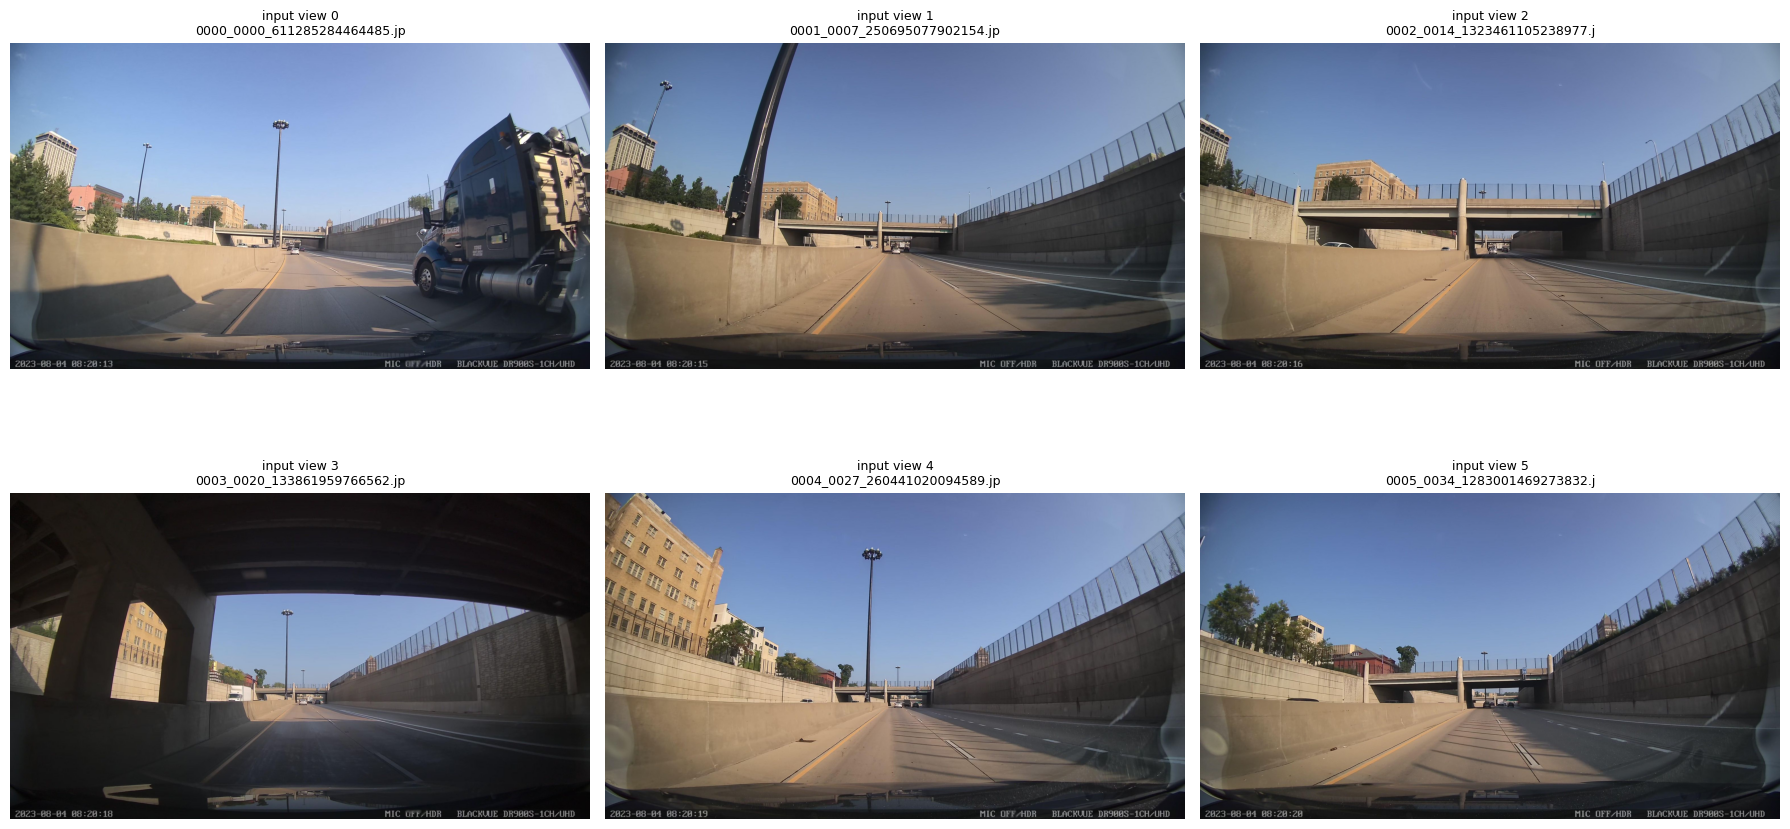

In [28]:
# 12a_show_original_2d_images_used_for_glb.py

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

img_dir = Path("/content/outputs/mapanything_input/images_6")
imgs = sorted(img_dir.glob("*.jpg"))

print("num images:", len(imgs))
for p in imgs:
    print(p.name)

plt.figure(figsize=(18, 10))

for i, p in enumerate(imgs):
    img = Image.open(p).convert("RGB")
    ax = plt.subplot(2, 3, i + 1)
    ax.imshow(img)
    ax.set_title(f"input view {i}\n{p.name[:28]}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()